<a href="https://colab.research.google.com/github/harshpp707/BIOL5340-Cancer-RNASeq-Feature-Selection/blob/anova-mi-l1/notebooks/03_Comparative_Feature_Selection_and_Stability.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 — Comparative Feature Selection, Model Sweep & Stability Analysis
**Project:** Evaluating Feature Selection Methods for Cancer Type Classification Using RNA-Seq Data  
**Team:** Harsh Patel, Omkar Juvatkar, Pritesh Das  
**Author (Notebook 03):** Omkar Juvatkar

### Objectives
1. **Leakage-Free Fold Ranking (Compute-Once Architecture):** Inside each stratified CV fold, remove constant (zero-variance) genes (`VarianceThreshold(0.0)`), standardize features (`StandardScaler`), and compute full rankings for **ANOVA F-test**, **Mutual Information (MI)**, and **L1-Regularized Logistic Regression** once per fold.
2. **Expanded Small-$k$ + Pilot Grid:** Evaluate $k \in \{1, 2, 3, 5, 10, 15, 25, 50, 100, 500\}$ and full $20,531$-feature baselines across **Linear SVM** (`LinearSVC`) and **Random Forest** (`RandomForestClassifier`) so method differences resolve clearly before the $k \ge 25$ saturation ceiling.
3. **Repeated Stratified CV ($3 \times 3$):** Quantify variance across small-$k$ subsets.
4. **Per-Class Recall, Confusion Matrices & Jaccard Stability:** Export all summary CSVs to `results/` and publication-ready plots to `results/figures/` without touching the 20% test holdout.

In [3]:
!pip -q install pydrive2

from pathlib import Path
from google.colab import auth, drive
import json, time, warnings
from itertools import combinations
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold, f_classif, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    f1_score, balanced_accuracy_score, recall_score, confusion_matrix
)

warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=RuntimeWarning)

drive.mount('/content/drive', force_remount=True)

# 1. Try finding X_expression.pkl anywhere inside /content/drive (Regardless of shortcut/folder name)
matches = list(Path('/content/drive').rglob('X_expression.pkl'))

if matches:
    DATA = matches[0].parent
    ROOT = DATA.parent
    RESULTS, FIGURES = ROOT/'results', ROOT/'results'/'figures'
    for p in [RESULTS, FIGURES]:
        p.mkdir(parents=True, exist_ok=True)
    print(f'Found dataset via Drive mount at: {DATA}')
else:
    # 2. Fallback: Fetch directly from "Shared with me" via Google Drive API
    print('Shortcut not detected in mount; pulling files directly from Shared with me via Drive API...')
    from pydrive2.auth import GoogleAuth
    from pydrive2.drive import GoogleDrive
    from oauth2client.client import GoogleCredentials
    auth.authenticate_user()
    gauth = GoogleAuth()
    gauth.credentials = GoogleCredentials.get_application_default()
    gdrive = GoogleDrive(gauth)

    ROOT = Path('/content/drive/MyDrive/BIOL5340_Cancer_RNASeq_Final_Project')
    DATA, RESULTS, FIGURES = ROOT/'data', ROOT/'results', ROOT/'results'/'figures'
    for p in [DATA, RESULTS, FIGURES]:
        p.mkdir(parents=True, exist_ok=True)

    for fname in ['X_expression.pkl', 'y_labels.csv', 'train_indices.npy']:
        dest = DATA / fname
        if not dest.exists():
            flist = gdrive.ListFile({'q': f"title = '{fname}' and trashed = false"}).GetList()
            if not flist:
                raise FileNotFoundError(f'Could not find {fname} in your Google account.')
            print(f'  Downloading {fname} ({int(flist[0].get("fileSize", 0))/1e6:.1f} MB)...')
            flist[0].GetContentFile(str(dest))

SEED = 42
FOLDS = 3
K_GRID = [1, 2, 3, 5, 10, 15, 25, 50, 100, 500]

X = pd.read_pickle(DATA/'X_expression.pkl')
y = pd.read_csv(DATA/'y_labels.csv')['cancer_type']
tr = np.load(DATA/'train_indices.npy')

Xtr = X.iloc[tr].reset_index(drop=True)
ytr = y.iloc[tr].reset_index(drop=True)
CLASSES = sorted(ytr.unique())
feature_names = np.array(Xtr.columns)

print(f'Workspace: {ROOT}')
print(f'Loaded Training Split: {Xtr.shape} | Classes: {CLASSES} | scikit-learn: {sklearn.__version__}')

Mounted at /content/drive
Found dataset via Drive mount at: /content/drive/MyDrive/BIOL5340_Cancer_RNASeq_Final_Project (1)/data
Workspace: /content/drive/MyDrive/BIOL5340_Cancer_RNASeq_Final_Project (1)
Loaded Training Split: (640, 20531) | Classes: ['BRCA', 'COAD', 'KIRC', 'LUAD', 'PRAD'] | scikit-learn: 1.6.1


## 1. Modular Ranking, Classifier & Stability Functions
To avoid redundant computation across $k \in K\_GRID$ and multiple classifiers, `compute_fold_rankings()` fits `VarianceThreshold(0.0)` and `StandardScaler()` strictly on each training fold and computes the full feature ordering once per fold for **ANOVA**, **MI**, and **L1**.

In [4]:
def compute_fold_rankings(X_train_fold, y_train_fold, seed=SEED):
    """
    Fits VarianceThreshold and StandardScaler strictly inside the training fold,
    then computes full feature rankings once per method (ANOVA, MI, L1).
    """
    vt = VarianceThreshold(threshold=0.0)
    X_vt = vt.fit_transform(X_train_fold)
    valid_cols = np.where(vt.get_support())[0]

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_vt)

    rankings = {}
    rank_times = {}

    # 1. Univariate ANOVA F-test
    t0 = time.perf_counter()
    f_scores, _ = f_classif(X_scaled, y_train_fold)
    f_scores = np.nan_to_num(f_scores, nan=-1.0)
    rankings['ANOVA'] = valid_cols[np.argsort(f_scores)[::-1]]
    rank_times['ANOVA'] = time.perf_counter() - t0

    # 2. Mutual Information (non-linear dependency)
    t0 = time.perf_counter()
    mi_scores = mutual_info_classif(
        X_scaled, y_train_fold, discrete_features=False, n_neighbors=3, random_state=seed
    )
    rankings['MI'] = valid_cols[np.argsort(mi_scores)[::-1]]
    rank_times['MI'] = time.perf_counter() - t0

    # 3. L1-Regularized Logistic Regression (mean |coef| across 5 tumor classes)
    t0 = time.perf_counter()
    l1_clf = LogisticRegression(
        penalty='l1', solver='saga', C=0.5, max_iter=500, random_state=seed, n_jobs=-1
    )
    l1_clf.fit(X_scaled, y_train_fold)
    l1_importance = np.mean(np.abs(l1_clf.coef_), axis=0)
    rankings['L1'] = valid_cols[np.argsort(l1_importance)[::-1]]
    rank_times['L1'] = time.perf_counter() - t0

    return vt, scaler, rankings, rank_times


def get_classifiers(seed=SEED):
    return {
        'LinearSVM': LinearSVC(dual='auto', max_iter=10000, random_state=seed),
        'RandomForest': RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=-1)
    }


def compute_jaccard_stability(fold_feature_sets):
    """Computes mean and std of pairwise Jaccard similarity across CV folds."""
    scores = []
    for s1, s2 in combinations(fold_feature_sets, 2):
        union = len(s1 | s2)
        scores.append(len(s1 & s2) / union if union > 0 else 1.0)
    return float(np.mean(scores)), float(np.std(scores))

## 2. Execute 3-Fold Stratified CV Sweep (ANOVA, MI, L1 × LinearSVM, RandomForest)
Reuses the exact `StratifiedKFold(n_splits=3, shuffle=True, random_state=42)` split from `02_Pilot_SVM.ipynb` for paired method comparison.

In [5]:
cv = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=SEED)

fold_cache = []
selected_sets = {m: {k: [] for k in K_GRID} for m in ['ANOVA', 'MI', 'L1']}

print('Step 1/2: Computing fold-level feature rankings (ANOVA, MI, L1)...')
for fold_idx, (train_idx, val_idx) in enumerate(cv.split(Xtr, ytr)):
    X_f_tr, y_f_tr = Xtr.iloc[train_idx].values, ytr.iloc[train_idx].values
    X_f_val, y_f_val = Xtr.iloc[val_idx].values, ytr.iloc[val_idx].values

    vt, scaler, rankings, rank_times = compute_fold_rankings(X_f_tr, y_f_tr, seed=SEED + fold_idx)

    X_tr_full_scaled = np.zeros_like(X_f_tr, dtype=np.float64)
    X_val_full_scaled = np.zeros_like(X_f_val, dtype=np.float64)
    valid_mask = vt.get_support()
    X_tr_full_scaled[:, valid_mask] = scaler.transform(vt.transform(X_f_tr))
    X_val_full_scaled[:, valid_mask] = scaler.transform(vt.transform(X_f_val))

    for m in ['ANOVA', 'MI', 'L1']:
        for k in K_GRID:
            selected_sets[m][k].append(set(feature_names[rankings[m][:k]]))

    fold_cache.append({
        'fold': fold_idx,
        'val_idx': val_idx,
        'X_tr_scaled': X_tr_full_scaled,
        'y_tr': y_f_tr,
        'X_val_scaled': X_val_full_scaled,
        'y_val': y_f_val,
        'rankings': rankings,
        'rank_times': rank_times
    })
    print(f"  Fold {fold_idx+1}/{FOLDS} ranked | Times (s): {{m: round(t, 2) for m, t in rank_times.items()}}")

print('\nStep 2/2: Evaluating classifiers across feature grid and computing full-feature baselines...')
results_rows = []
per_class_rows = []
oof_predictions = {}

for method in ['ANOVA', 'MI', 'L1']:
    for clf_name in ['LinearSVM', 'RandomForest']:
        for k in K_GRID:
            fold_f1s, fold_bas, fold_times = [], [], []
            oof_preds = np.empty(len(ytr), dtype=object)

            for f_data in fold_cache:
                top_k_idx = f_data['rankings'][method][:k]
                clf = get_classifiers(SEED)[clf_name]

                t0 = time.perf_counter()
                clf.fit(f_data['X_tr_scaled'][:, top_k_idx], f_data['y_tr'])
                preds = clf.predict(f_data['X_val_scaled'][:, top_k_idx])
                clf_time = time.perf_counter() - t0

                oof_preds[f_data['val_idx']] = preds
                fold_f1s.append(f1_score(f_data['y_val'], preds, average='macro'))
                fold_bas.append(balanced_accuracy_score(f_data['y_val'], preds))
                fold_times.append(f_data['rank_times'][method] + clf_time)

            j_mean, j_std = compute_jaccard_stability(selected_sets[method][k])
            oof_predictions[(method, clf_name, k)] = oof_preds

            results_rows.append({
                'method': method,
                'classifier': clf_name,
                'n_features': k,
                'macro_f1_mean': np.mean(fold_f1s),
                'macro_f1_std': np.std(fold_f1s),
                'balanced_accuracy_mean': np.mean(fold_bas),
                'jaccard_mean': j_mean,
                'jaccard_std': j_std,
                'run_seconds': np.sum(fold_times),
                'fold_macro_f1': json.dumps([round(x, 6) for x in fold_f1s])
            })

            recalls = recall_score(ytr, oof_preds, labels=CLASSES, average=None)
            per_class_rows.append({
                'method': method, 'classifier': clf_name, 'n_features': k,
                **{f'recall_{c}': r for c, r in zip(CLASSES, recalls)}
            })

# Full-Feature Baselines (20,531 features)
for clf_name in ['LinearSVM', 'RandomForest']:
    fold_f1s, fold_bas, fold_times = [], [], []
    oof_preds = np.empty(len(ytr), dtype=object)
    for f_data in fold_cache:
        clf = get_classifiers(SEED)[clf_name]
        t0 = time.perf_counter()
        clf.fit(f_data['X_tr_scaled'], f_data['y_tr'])
        preds = clf.predict(f_data['X_val_scaled'])
        fold_times.append(time.perf_counter() - t0)
        oof_preds[f_data['val_idx']] = preds
        fold_f1s.append(f1_score(f_data['y_val'], preds, average='macro'))
        fold_bas.append(balanced_accuracy_score(f_data['y_val'], preds))

    oof_predictions[('none', clf_name, Xtr.shape[1])] = oof_preds
    results_rows.append({
        'method': 'none', 'classifier': clf_name, 'n_features': Xtr.shape[1],
        'macro_f1_mean': np.mean(fold_f1s), 'macro_f1_std': np.std(fold_f1s),
        'balanced_accuracy_mean': np.mean(fold_bas), 'jaccard_mean': 1.0, 'jaccard_std': 0.0,
        'run_seconds': np.sum(fold_times),
        'fold_macro_f1': json.dumps([round(x, 6) for x in fold_f1s])
    })
    recalls = recall_score(ytr, oof_preds, labels=CLASSES, average=None)
    per_class_rows.append({
        'method': 'none', 'classifier': clf_name, 'n_features': Xtr.shape[1],
        **{f'recall_{c}': r for c, r in zip(CLASSES, recalls)}
    })

comp_df = pd.DataFrame(results_rows)
recall_df = pd.DataFrame(per_class_rows)

comp_df.to_csv(RESULTS/'comparative_cv_results.csv', index=False)
recall_df.to_csv(RESULTS/'per_class_recall_summary.csv', index=False)
print('Saved results/comparative_cv_results.csv and results/per_class_recall_summary.csv')
display(comp_df)

Step 1/2: Computing fold-level feature rankings (ANOVA, MI, L1)...
  Fold 1/3 ranked | Times (s): {m: round(t, 2) for m, t in rank_times.items()}
  Fold 2/3 ranked | Times (s): {m: round(t, 2) for m, t in rank_times.items()}
  Fold 3/3 ranked | Times (s): {m: round(t, 2) for m, t in rank_times.items()}

Step 2/2: Evaluating classifiers across feature grid and computing full-feature baselines...
Saved results/comparative_cv_results.csv and results/per_class_recall_summary.csv


,method,classifier,n_features,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,jaccard_mean,jaccard_std,run_seconds,fold_macro_f1
0,ANOVA,LinearSVM,1,0.322039,0.003500,0.398333,1.000000,0.000000,0.409267,"[0.31709, 0.324514, 0.324514]"
1,ANOVA,LinearSVM,2,0.427117,0.028284,0.478810,1.000000,0.000000,0.410396,"[0.431778, 0.45919, 0.390382]"
2,ANOVA,LinearSVM,3,0.642062,0.029342,0.663881,0.500000,0.000000,0.407628,"[0.629515, 0.68259, 0.614081]"
3,ANOVA,LinearSVM,5,0.861908,0.033283,0.848937,1.000000,0.000000,0.408158,"[0.833877, 0.90867, 0.843176]"
4,ANOVA,LinearSVM,10,0.954774,0.030043,0.947086,0.674437,0.114327,0.410144,"[0.942755, 0.925492, 0.996075]"
...,...,...,...,...,...,...,...,...,...,...
57,L1,RandomForest,50,0.998673,0.001877,0.998198,0.587568,0.020578,837.481337,"[1.0, 1.0, 0.996018]"
58,L1,RandomForest,100,0.997370,0.001860,0.996444,0.645036,0.044283,836.971211,"[0.996091, 1.0, 0.996018]"
59,L1,RandomForest,500,0.996095,0.003187,0.994734,0.658411,0.007753,837.442570,"[0.996091, 1.0, 0.992194]"
60,none,LinearSVM,20531,0.997485,0.003557,0.998246,1.000000,0.000000,17.502232,"[0.992455, 1.0, 1.0]"


## 3. Repeated Stratified CV ($3 \times 3 = 9$ Splits) on Small-$k$ Grid
Runs `RepeatedStratifiedKFold(n_splits=3, n_repeats=3, random_state=42)` across $k \in \{1, 2, 3, 5, 10, 15, 25\}$ to verify method separation with tighter confidence intervals.

In [6]:
rskf = RepeatedStratifiedKFold(n_splits=3, n_repeats=3, random_state=SEED)
SMALL_K = [1, 2, 3, 5, 10, 15, 25]
rep_rows = []

for split_idx, (train_idx, val_idx) in enumerate(rskf.split(Xtr, ytr)):
    X_f_tr, y_f_tr = Xtr.iloc[train_idx].values, ytr.iloc[train_idx].values
    X_f_val, y_f_val = Xtr.iloc[val_idx].values, ytr.iloc[val_idx].values

    vt = VarianceThreshold(0.0)
    scaler = StandardScaler()
    X_tr_s = scaler.fit_transform(vt.fit_transform(X_f_tr))
    X_val_s = scaler.transform(vt.transform(X_f_val))

    f_scores = np.nan_to_num(f_classif(X_tr_s, y_f_tr)[0], nan=-1.0)
    anova_order = np.argsort(f_scores)[::-1]

    l1_clf = LogisticRegression(penalty='l1', solver='saga', C=0.5, max_iter=300, random_state=SEED+split_idx, n_jobs=-1)
    l1_clf.fit(X_tr_s, y_f_tr)
    l1_order = np.argsort(np.mean(np.abs(l1_clf.coef_), axis=0))[::-1]

    for m_name, order in [('ANOVA', anova_order), ('L1', l1_order)]:
        for k in SMALL_K:
            cols = order[:k]
            for c_name, clf in get_classifiers(SEED).items():
                clf.fit(X_tr_s[:, cols], y_f_tr)
                preds = clf.predict(X_val_s[:, cols])
                rep_rows.append({
                    'split': split_idx, 'method': m_name, 'classifier': c_name, 'n_features': k,
                    'macro_f1': f1_score(y_f_val, preds, average='macro')
                })

rep_df = (
    pd.DataFrame(rep_rows)
    .groupby(['method', 'classifier', 'n_features'])['macro_f1']
    .agg(macro_f1_mean='mean', macro_f1_std='std')
    .reset_index()
)
rep_df.to_csv(RESULTS/'repeated_cv_small_k.csv', index=False)
print('Saved results/repeated_cv_small_k.csv')
display(rep_df)

Saved results/repeated_cv_small_k.csv


,method,classifier,n_features,macro_f1_mean,macro_f1_std
0,ANOVA,LinearSVM,1,0.320934,0.004513
1,ANOVA,LinearSVM,2,0.465089,0.059247
2,ANOVA,LinearSVM,3,0.647269,0.062393
3,ANOVA,LinearSVM,5,0.819924,0.095067
4,ANOVA,LinearSVM,10,0.944875,0.047541
5,ANOVA,LinearSVM,15,0.992376,0.008262
6,ANOVA,LinearSVM,25,0.996991,0.003682
7,ANOVA,RandomForest,1,0.436198,0.020689
8,ANOVA,RandomForest,2,0.580961,0.033482
9,ANOVA,RandomForest,3,0.713030,0.070574


## 4. Generate Figures for Report (`results/figures/`)
Generates:
1. `comparative_f1_vs_k.png`: 3-Fold CV Macro-F1 vs. $k$ for LinearSVM and RandomForest across ANOVA, MI, and L1.
2. `jaccard_stability_vs_k.png`: Pairwise Jaccard feature stability across CV folds.
3. `confusion_matrices_k10.png` & `confusion_matrices_k25.png`: Out-of-fold confusion matrices across the 5 cancer types.

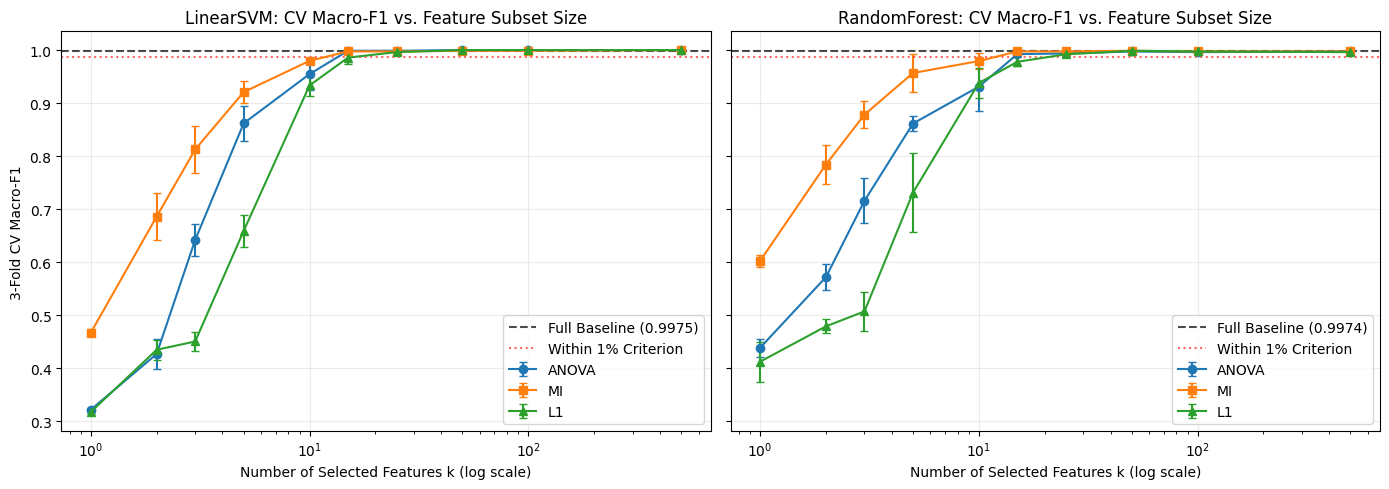

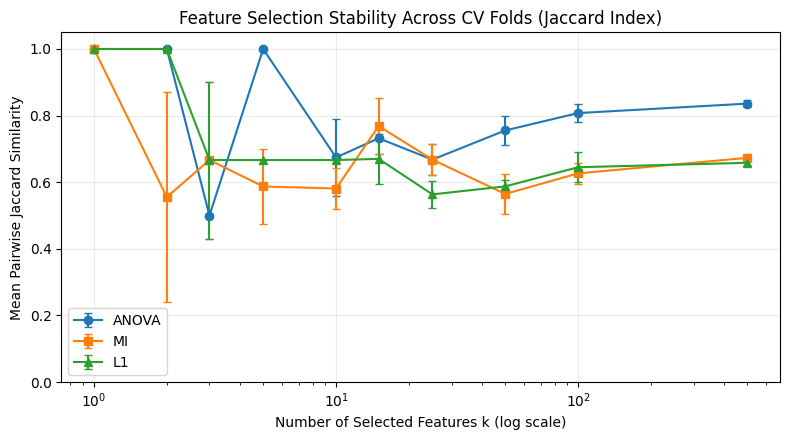

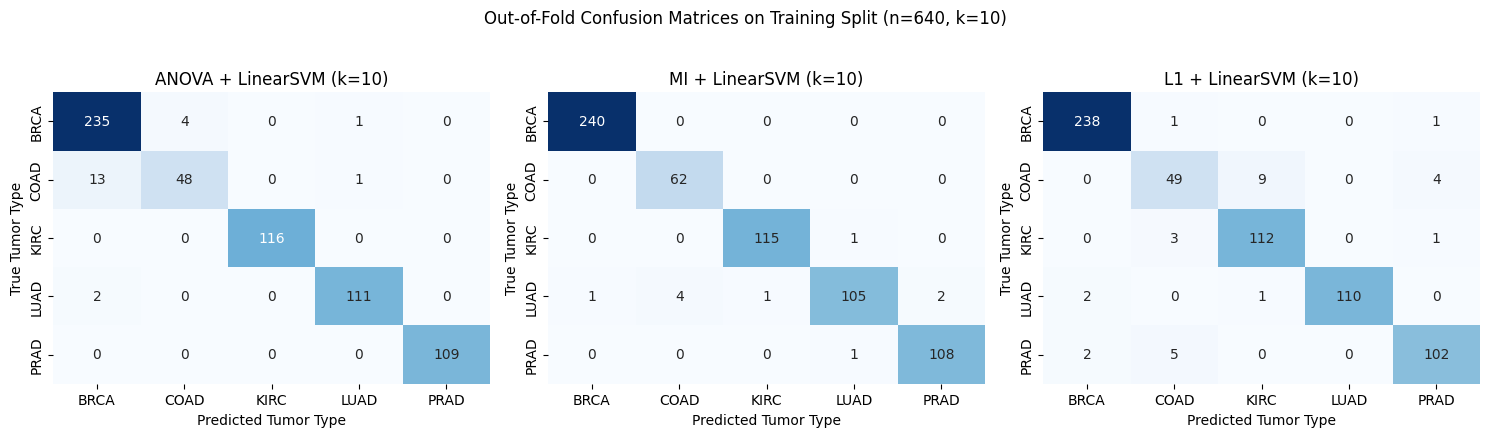

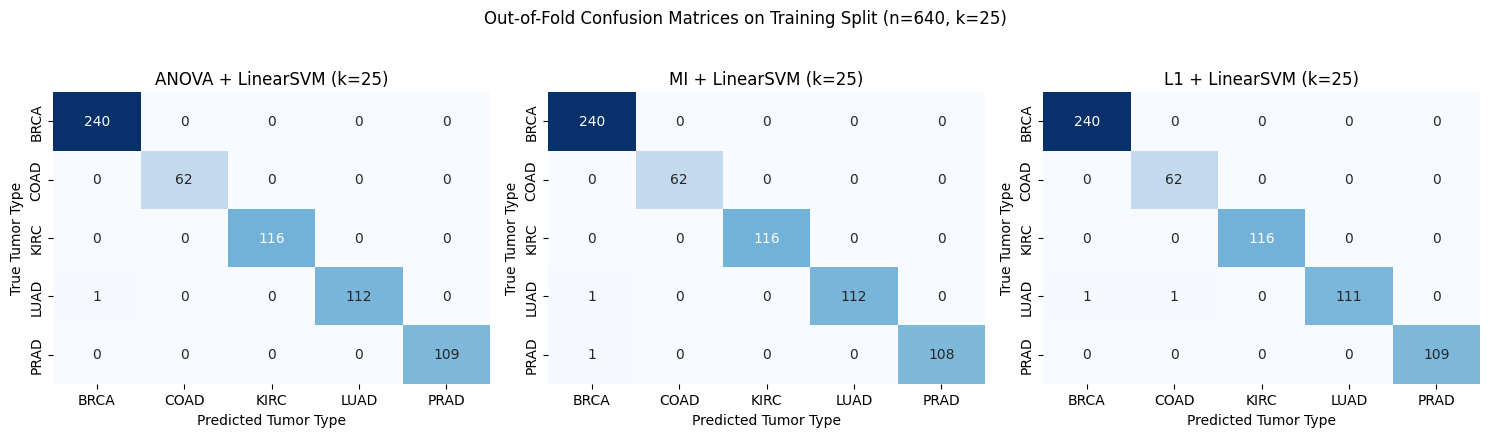

In [7]:
# 1. Macro-F1 vs Feature Count (LinearSVM vs RandomForest)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
sub_df = comp_df[comp_df['method'] != 'none']

for ax, clf_name in zip(axes, ['LinearSVM', 'RandomForest']):
    base_f1 = comp_df[(comp_df['method']=='none') & (comp_df['classifier']==clf_name)]['macro_f1_mean'].values[0]
    for method, marker in [('ANOVA', 'o'), ('MI', 's'), ('L1', '^')]:
        m_df = sub_df[(sub_df['classifier']==clf_name) & (sub_df['method']==method)].sort_values('n_features')
        ax.errorbar(
            m_df['n_features'], m_df['macro_f1_mean'], yerr=m_df['macro_f1_std'],
            label=method, marker=marker, capsize=3
        )
    ax.axhline(base_f1, color='black', linestyle='--', alpha=0.7, label=f'Full Baseline ({base_f1:.4f})')
    ax.axhline(base_f1 - 0.01, color='red', linestyle=':', alpha=0.6, label='Within 1% Criterion')
    ax.set_xscale('log')
    ax.set_xlabel('Number of Selected Features k (log scale)')
    ax.set_title(f'{clf_name}: CV Macro-F1 vs. Feature Subset Size')
    ax.grid(alpha=0.25)
    ax.legend(loc='lower right')

axes[0].set_ylabel('3-Fold CV Macro-F1')
fig.tight_layout()
fig.savefig(FIGURES/'comparative_f1_vs_k.png', dpi=180)
plt.show()

# 2. Jaccard Stability Curve across k
fig, ax = plt.subplots(figsize=(8, 4.5))
stab_df = sub_df[sub_df['classifier']=='LinearSVM'].sort_values('n_features')
for method, marker in [('ANOVA', 'o'), ('MI', 's'), ('L1', '^')]:
    m_df = stab_df[stab_df['method']==method]
    ax.errorbar(
        m_df['n_features'], m_df['jaccard_mean'], yerr=m_df['jaccard_std'],
        label=method, marker=marker, capsize=3
    )
ax.set_xscale('log')
ax.set_xlabel('Number of Selected Features k (log scale)')
ax.set_ylabel('Mean Pairwise Jaccard Similarity')
ax.set_title('Feature Selection Stability Across CV Folds (Jaccard Index)')
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES/'jaccard_stability_vs_k.png', dpi=180)
plt.show()

# 3. Out-of-Fold Confusion Matrices at k=10 and k=25
for k_plot in [10, 25]:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
    for ax, method in zip(axes, ['ANOVA', 'MI', 'L1']):
        preds = oof_predictions[(method, 'LinearSVM', k_plot)]
        cm = confusion_matrix(ytr, preds, labels=CLASSES)
        sns.heatmap(
            cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASSES, yticklabels=CLASSES, cbar=False, ax=ax
        )
        ax.set_title(f'{method} + LinearSVM (k={k_plot})')
        ax.set_xlabel('Predicted Tumor Type')
        ax.set_ylabel('True Tumor Type')
    fig.suptitle(f'Out-of-Fold Confusion Matrices on Training Split (n=640, k={k_plot})', y=1.03)
    fig.tight_layout()
    fig.savefig(FIGURES/f'confusion_matrices_k{k_plot}.png', dpi=180, bbox_inches='tight')
    plt.show()